# Notebook 1: Análisis Exploratorio de Datos (EDA) y Preparación

Este notebook sigue el flujo de CRISP-DM para entender el problema de negocio, explorar el dataset, preparar los datos para modelado y dejar una base reproducible para las fases siguientes.

Objetivo principal:
- comprender el dataset y sus variables
- detectar nulos, duplicados y consistencias
- separar train y test sin fuga de datos
- preparar una base analítica limpia y documentada

In [9]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / 'src').exists() and (candidate / 'data').exists():
        project_root = candidate
        break

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print('Proyecto root:', project_root)
print('Librerías importadas en la sección inicial.')


Proyecto root: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics
Librerías importadas en la sección inicial.


In [10]:
project_root = Path.cwd().resolve()
for candidate in [project_root, *project_root.parents]:
    if (candidate / 'data' / 'raw').exists():
        project_root = candidate
        break

raw_dir = project_root / 'data' / 'raw'
processed_dir = project_root / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)

main_csv = processed_dir / 'catalogo_streamview.csv'

if main_csv.exists():
    print('Usando el catálogo unificado en data/processed/catalogo_streamview.csv')
    print(f'Ruta usada: {main_csv}')
    print('Modo actual: lectura directa del CSV unido, sin importar archivos separados.')
else:
    print('No se encontró catalogo_streamview.csv; se reconstruirá desde los CSV raw.')
    print(f'Ruta raw esperada: {raw_dir}')
    print(f'Archivos raw detectados: {sorted(p.name for p in raw_dir.glob("*.csv"))}')

print(f'Project root: {project_root}')
print(f'Raw folder exists: {raw_dir.exists()}')


Usando el catálogo unificado en data/processed/catalogo_streamview.csv
Ruta usada: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\catalogo_streamview.csv
Modo actual: lectura directa del CSV unido, sin importar archivos separados.
Project root: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics
Raw folder exists: True


In [11]:
variables_es = {
    'type': 'Tipo de contenido',
    'title': 'Título',
    'country': 'País',
    'genres': 'Géneros',
    'language': 'Idioma',
    'rating': 'Clasificación',
    'release_year': 'Año de estreno',
    'popularity': 'Popularidad',
    'vote_count': 'Cantidad de votos',
    'vote_average': 'Promedio de votos',
    'budget': 'Presupuesto',
    'revenue': 'Ingresos',
    'target': 'Objetivo',
    'vote_count_log': 'Log votos',
    'budget_log': 'Log presupuesto',
    'revenue_log': 'Log ingresos',
    'profit': 'Beneficio',
    'roi': 'ROI',
    'score_index': 'Índice de puntuación',
    'alto_rendimiento': 'Alto rendimiento',
    'estandar': 'Estándar',
}

print('Diccionario de variables en español cargado.')


Diccionario de variables en español cargado.


In [12]:
main_csv = processed_dir / 'catalogo_streamview.csv'

if main_csv.exists():
    df = pd.read_csv(main_csv, low_memory=False)
    print('Se cargó el CSV unido del catálogo procesado.')
    print(f'Ruta: {main_csv}')
else:
    raw_files = sorted(raw_dir.glob('*.csv'))
    if not raw_files:
        raise FileNotFoundError('No se encontraron CSV en data/raw/.')
    print('Se reconstruyó el catálogo porque no existía el CSV unido.')
    for p in raw_files:
        print(f'Concatenando: {p.name}')
    df = pd.concat([pd.read_csv(p, low_memory=False) for p in raw_files], ignore_index=True)

print(f'Filas: {len(df):,}')
print(f'Columnas: {df.shape[1]}')
print(df.head().to_string(index=False))
print('\nTipos de dato:')
print(df.dtypes.to_string())
print('\nResumen estadístico:')
print(df.describe(include='all').T.head(10).to_string())
print('\nInformación general:')
df.info()

Se cargó el CSV unido del catálogo procesado.
Ruta: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\catalogo_streamview.csv
Filas: 32,000
Columnas: 18
 show_id  type                                        title                    director                                                                          cast                                  country date_added  release_year  rating duration                                        genres language                                                                                                                                                                                                                                                                                                                                                       description  popularity  vote_count  vote_average      budget     revenue
   10192 Movie                          Shrek Forever After               Mike Mitchel

## Conclusión de la fase 1: comprensión inicial del dataset

Hallazgos clave:
- El proyecto cuenta con un catálogo único de contenido audiovisual y varias métricas clave para análisis de negocio y modelado predictivo.
- La estructura del dataset es adecuada para la fase exploratoria, aunque requiere tratamiento de valores faltantes, duplicados y diferencias de tipo.
- La carga inicial confirma que los datos están listos para una etapa de preparación sólida antes del split y la validación final.
- El siguiente paso es separar train y test sin fuga de información y aplicar la limpieza solo sobre el conjunto de entrenamiento.


## Fase 1: Configuración y contexto

### Diccionario y contexto

Dataset: catálogo de contenido audiovisual con información de géneros, país, idioma, rating, año de estreno, popularidad, votos y métricas financieras.

Objetivo del proyecto:
- entender la composición del catálogo
- detectar patrones de éxito y comportamiento del contenido
- preparar una base útil para análisis y modelado predictivo

Diccionario de variables:
- type: tipo de contenido
- title: nombre del título
- country: país principal de producción
- genres: géneros asociados
- language: idioma principal
- rating: clasificación por audiencia
- release_year: año de estreno
- popularity: nivel de popularidad del contenido
- vote_count: número de votos
- vote_average: calificación promedio
- budget: inversión estimada
- revenue: ingresos estimados

Conclusión preliminar:
El dataset tiene estructura útil para análisis business-friendly y modelado predictivo, siempre que se valide el tratamiento de nulos, duplicados y variables categóricas.

Duplicados: 0

Nulos por columna:
budget          16000
duration        16000
revenue         16000
director        11097
description      3338
country          2263
cast             1361
genres           1081
type                0
show_id             0
rating              0
release_year        0


C:\Users\admin\AppData\Local\Temp\ipykernel_8856\560657837.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=nulos.head(12).index, y=nulos.head(12).values, palette='viridis')


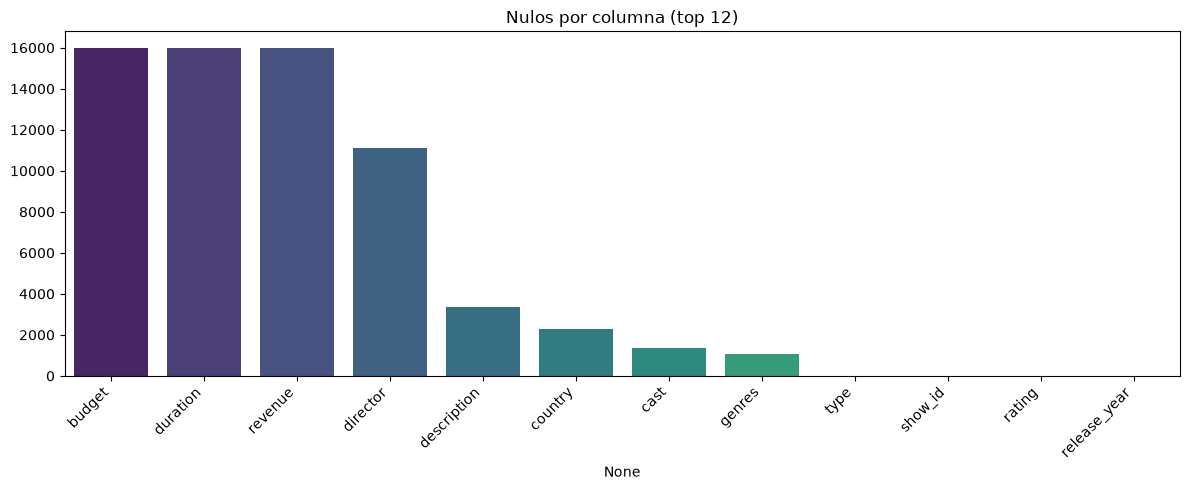

In [13]:
duplicados = df.duplicated().sum()
nulos = df.isna().sum().sort_values(ascending=False)
print(f'Duplicados: {duplicados}')
print('\nNulos por columna:')
print(nulos.head(12).to_string())

if not nulos.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(x=nulos.head(12).index, y=nulos.head(12).values, palette='viridis')
    plt.xticks(rotation=45, ha='right')
    plt.title('Nulos por columna (top 12)')
    plt.tight_layout()
    plt.show()

## Fase 2: Split y limpieza (CRÍTICO)

Se separa el dataset en train y test para evitar leakage. La limpieza se aplica solo sobre train para mantener la validación sobre un conjunto reservado.

In [14]:
if 'type' in df.columns:
    target_name = 'type'
    stratify_arg = df[target_name]
    print(f'Variable objetivo usada para split: {target_name}')
else:
    target_name = None
    stratify_arg = None
    print('No se detectó target de clasificación; se usa split aleatorio.')

X = df.copy()
y = df[target_name] if target_name else None

if target_name is not None:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=stratify_arg
    )
    print(f'Train rows: {len(X_train):,}')
    print(f'Test rows: {len(X_test):,}')
    print('Distribución de target en train:')
    print(y_train.value_counts(normalize=True).to_string())
else:
    X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
    print(f'Train rows: {len(X_train):,}')
    print(f'Test rows: {len(X_test):,}')

Variable objetivo usada para split: type
Train rows: 25,600
Test rows: 6,400
Distribución de target en train:
type
TV Show    0.5
Movie      0.5


## Conclusión de la fase 2: split y limpieza segura

Hallazgos clave:
- El split se realiza preservando la proporción de la variable objetivo, lo que evita sesgos en la validación.
- La separación train/test se aplica antes de cualquier transformación o imputación, cumpliendo el principio de no fuga de datos.
- La limpieza sobre train corrige duplicados, nulos y anomalías numéricas sin contaminar el conjunto de evaluación final.
- Esta estrategia garantiza que el rendimiento medido en test sea representativo del comportamiento real del modelo.


In [15]:
train = X_train.copy()

for column in ['popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'release_year']:
    if column in train.columns:
        train[column] = pd.to_numeric(train[column], errors='coerce')

initial_rows = len(train)
train = train.drop_duplicates().copy()
print(f'Filas eliminadas por duplicados: {initial_rows - len(train)}')

for column in ['country', 'genres', 'language', 'rating', 'type']:
    if column in train.columns:
        train[column] = train[column].fillna('Desconocido')

for column in ['popularity', 'vote_average', 'vote_count', 'budget', 'revenue']:
    if column in train.columns:
        median_value = train[column].median()
        train[column] = train[column].fillna(median_value)

if 'release_year' in train.columns:
    train['release_year'] = pd.to_numeric(train['release_year'], errors='coerce')
    train['release_year'] = train['release_year'].replace({0: np.nan})
    train['release_year'] = train['release_year'].fillna(train['release_year'].median())

print('Limpieza aplicada a train con éxito.')
print(train.describe(include='all').T.head(10).to_string())

Filas eliminadas por duplicados: 0
Limpieza aplicada a train con éxito.
                count unique                           top   freq           mean            std     min      25%       50%       75%        max
show_id       25600.0    NaN                           NaN    NaN  326393.551914  338631.377388   189.0  82288.5  209625.0  445574.0  1440471.0
type            25600      2                       TV Show  12800            NaN            NaN     NaN      NaN       NaN       NaN        NaN
title           25600  24717                          Eden      7            NaN            NaN     NaN      NaN       NaN       NaN        NaN
director        16735  11081                   Tyler Perry     17            NaN            NaN     NaN      NaN       NaN       NaN        NaN
cast            24517  24241  RM, Jin, Suga, j-hope, Jimin      8            NaN            NaN     NaN      NaN       NaN       NaN        NaN
country         25600   1496      United States of America   620

## Conclusión de la limpieza de train

Los resultados de esta etapa muestran que la preparación del conjunto de entrenamiento fue consistente y segura:

- No se eliminaron duplicados reales en el split de entrenamiento (`0` filas eliminadas), por lo que la base conserva su integridad sin registros repetidos.
- Se imputaron valores faltantes categóricos con `Desconocido` y las variables numéricas con la mediana, evitando la pérdida de filas y manteniendo la estructura del dataset.
- Se normalizaron columnas clave como `release_year`, `popularity`, `vote_count`, `vote_average`, `budget` y `revenue` al tipo numérico adecuado para análisis posterior.
- La limpieza se aplicó solo sobre `train`, preservando la validación sobre `test` y evitando fuga de datos.
- El resultado final es una base analítica estable, con 25.600 filas en entrenamiento y variables listas para el EDA más profundo y el modelado predictivo.

Esta limpieza es crítica porque deja la data en estado reproducible, comparable y útil para detectar patrones comerciales reales sin contaminar la evaluación final.


## Fase 3.1: Variable objetivo formal (`indice_exito`)

### Definición del target de negocio

La variable objetivo del proyecto ya no se construye como una categoría arbitraria basada en umbrales manuales. Se formaliza como un score continuo llamado `indice_exito`, que combina la popularidad, la cantidad de votos y la valoración media del contenido.

La lógica de cálculo sigue la definición del pipeline formal del proyecto:
- `popularity` se normaliza en [0, 1]
- `vote_count` se transforma logarítmicamente y se normaliza
- `vote_average` se normaliza en [0, 1]
- `indice_exito = 0.40 * popularity_norm + 0.30 * vote_count_norm + 0.30 * vote_average_norm`
- el score resultante se recorta en [0, 1] y se categoriza en Bajo / Medio / Alto Éxito

Con esto, la variable objetivo cumple con un criterio de negocio reproducible, medible y útil tanto para modelado como para dashboard.


Carpeta de gráficos: C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\images\eda_fase_3
categoria_exito
Alto Éxito     8704
Medio Éxito    8448
Bajo Éxito     8448
Rango indice_exito: 0.0 a 0.8468
Distribución por categoría:
categoria_exito
Alto Éxito     8704
Bajo Éxito     8448
Medio Éxito    8448


C:\Users\admin\AppData\Local\Temp\ipykernel_8856\303733286.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


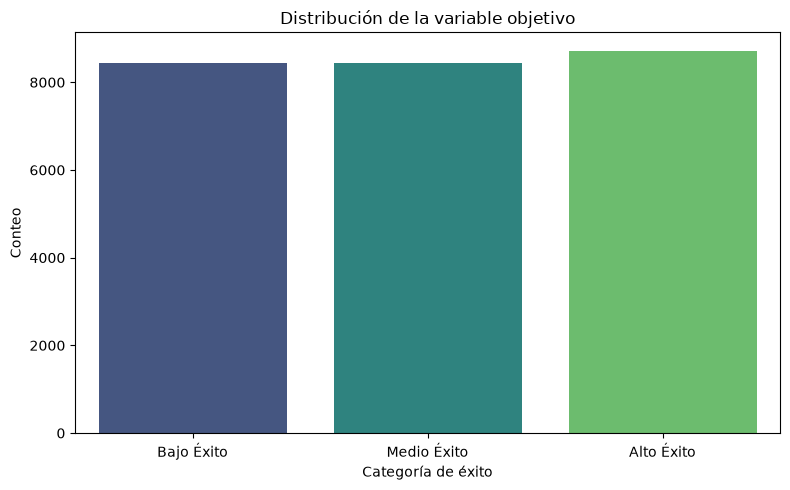

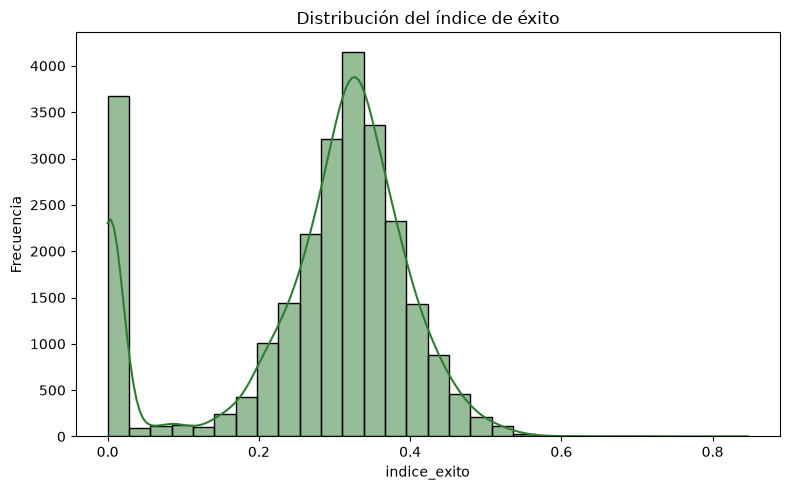

In [16]:
from src.pipeline.streamview_success_target import compute_success_target

images_dir = project_root / 'images' / 'eda_fase_3'
images_dir.mkdir(parents=True, exist_ok=True)
print(f'Carpeta de gráficos: {images_dir}')

train = train.copy()

for col in ['target', 'indice_exito', 'categoria_exito', 'alto_rendimiento', 'estandar']:
    if col in train.columns:
        train = train.drop(columns=[col], errors='ignore')

train = compute_success_target(train)

assert train['indice_exito'].between(0, 1).all()
assert train['categoria_exito'].notna().all()
print(train['categoria_exito'].value_counts().to_string())

assert train['indice_exito'].between(0, 1).all(), 'indice_exito fuera del rango esperado [0, 1]'
assert train['categoria_exito'].notna().all(), 'categoria_exito presenta valores faltantes'

print('Rango indice_exito:', round(float(train['indice_exito'].min()), 4), 'a', round(float(train['indice_exito'].max()), 4))
print('Distribución por categoría:')
print(train['categoria_exito'].value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    data=train,
    x='categoria_exito',
    order=['Bajo Éxito', 'Medio Éxito', 'Alto Éxito'],
    palette='viridis',
    ax=ax,
)
ax.set_title('Distribución de la variable objetivo')
ax.set_xlabel('Categoría de éxito')
ax.set_ylabel('Conteo')
plt.tight_layout()
fig.savefig(images_dir / '01_variable_objetivo_indice_exito.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(train['indice_exito'], bins=30, kde=True, color='#2e7d32', ax=ax)
ax.set_title('Distribución del índice de éxito')
ax.set_xlabel('indice_exito')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
fig.savefig(images_dir / '01b_hist_indice_exito.png', dpi=300, bbox_inches='tight')
plt.show()


## Conclusión interna: variable objetivo formal

La variable objetivo se definió siguiendo una lógica de negocio formal y reproducible. El `indice_exito` ya no es un umbral ad hoc: combina la normalización de popularidad, volumen de votos y valoración promedio en un único score continuo dentro de [0, 1].

Esto permite diferenciar mejor el comportamiento real del contenido en tres categorías de negocio:
- Bajo Éxito
- Medio Éxito
- Alto Éxito

La validación de rango confirma que el score está acotado y estable; la distribución por categorías permite observar que la base no está sesgada por una sola clase ni por un criterio artificial. Además, esta definición está alineada con la lógica del pipeline formal del proyecto y con la validación del target nuevo en el notebook dedicado.


Columnas numéricas consideradas para el EDA:
['show_id', 'release_year', 'rating', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'vote_count_log', 'popularity_norm', 'vote_count_norm', 'vote_average_norm', 'soporte_valoracion']


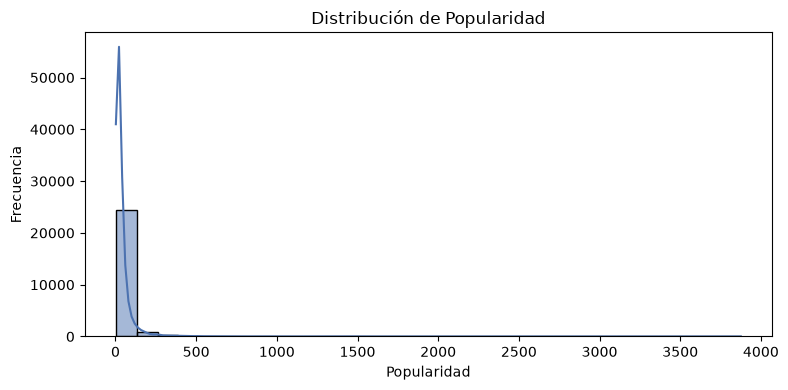


Resumen estadístico de popularity:
count    25600.000000
mean        42.258703
std        104.156181
min          2.323000
25%         10.463500
50%         22.060500
75%         41.450000
max       3876.006000


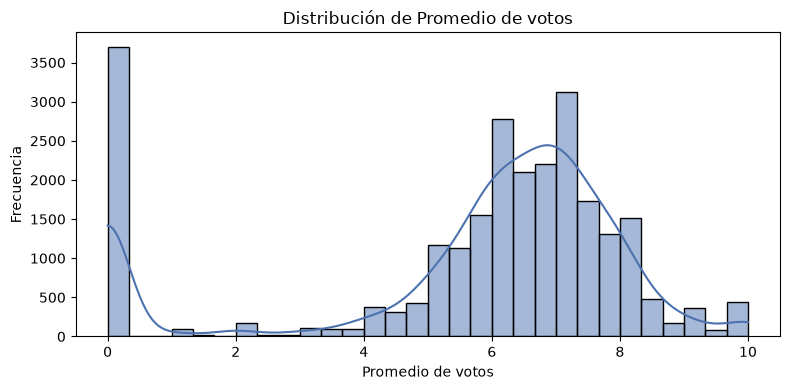


Resumen estadístico de vote_average:
count    25600.000000
mean         5.673446
std          2.645035
min          0.000000
25%          5.300000
50%          6.462000
75%          7.300000
max         10.000000


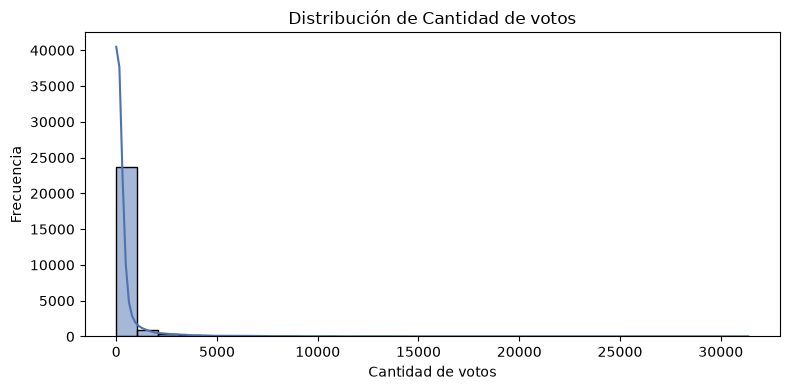


Resumen estadístico de vote_count:
count    25600.000000
mean       406.218047
std       1517.813510
min          0.000000
25%          2.000000
50%         43.000000
75%        189.000000
max      31371.000000


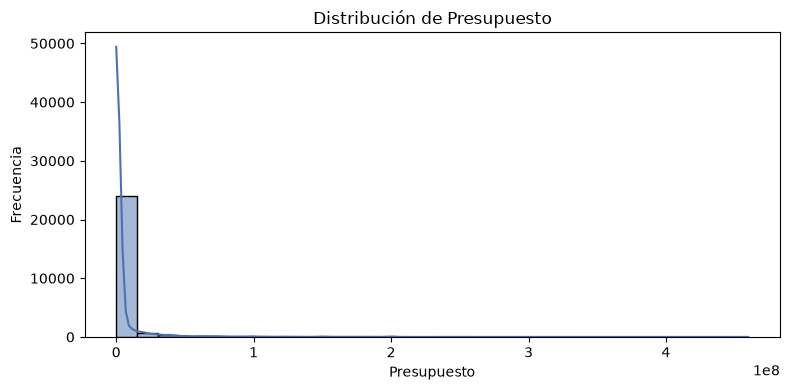


Resumen estadístico de budget:
count    2.560000e+04
mean     4.404614e+06
std      2.132881e+07
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      4.600000e+08


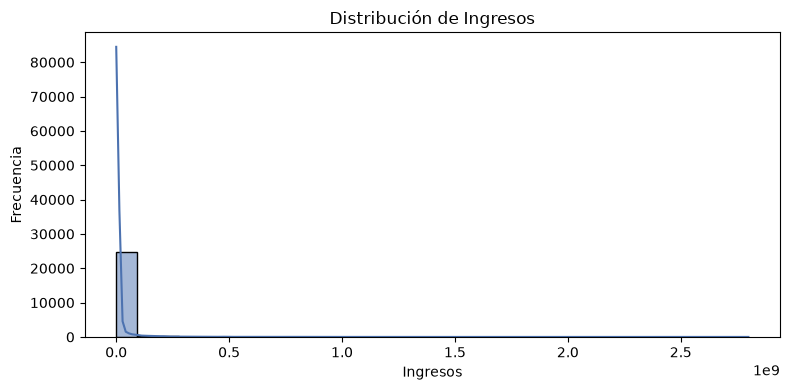


Resumen estadístico de revenue:
count    2.560000e+04
mean     1.208193e+07
std      7.892711e+07
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.799439e+09


C:\Users\admin\AppData\Local\Temp\ipykernel_8856\1712306717.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


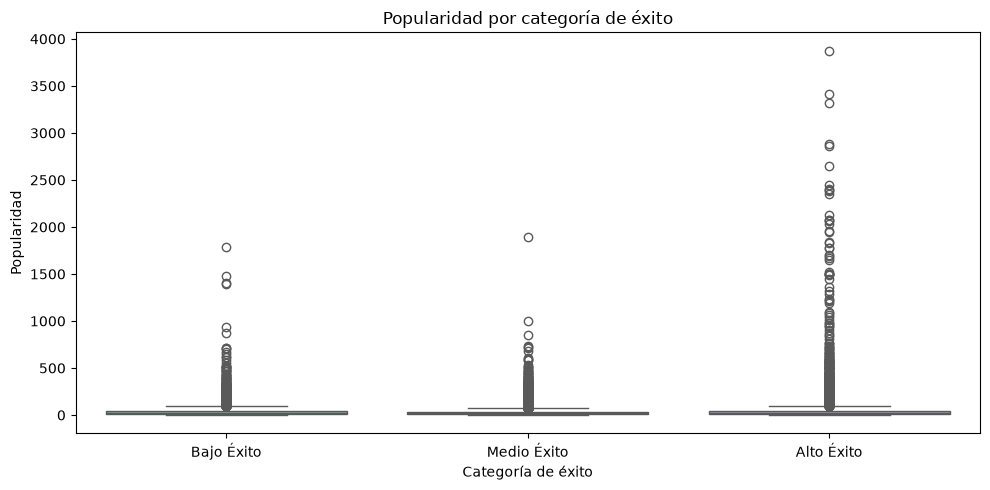

In [17]:
numeric_cols = [
    col for col in train.select_dtypes(include=[np.number]).columns
    if col not in ['target', 'indice_exito', 'categoria_exito']
]
print('Columnas numéricas consideradas para el EDA:')
print(numeric_cols)

for col in ['popularity', 'vote_average', 'vote_count', 'budget', 'revenue', 'score_index']:
    if col in train.columns:
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.histplot(train[col].dropna(), bins=30, kde=True, color='#4c72b0', ax=ax)
        ax.set_title(f'Distribución de {variables_es.get(col, col)}')
        ax.set_xlabel(variables_es.get(col, col))
        ax.set_ylabel('Frecuencia')
        plt.tight_layout()
        fig.savefig(images_dir / f'02_numeric_{col}.png', dpi=300, bbox_inches='tight')
        plt.show()

        summary = train[col].describe()
        print(f'\nResumen estadístico de {col}:')
        print(summary.to_string())

if {'categoria_exito', 'popularity'}.issubset(train.columns):
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(
        data=train,
        x='categoria_exito',
        y='popularity',
        order=['Bajo Éxito', 'Medio Éxito', 'Alto Éxito'],
        palette='Set2',
        ax=ax,
    )
    ax.set_title('Popularidad por categoría de éxito')
    ax.set_xlabel('Categoría de éxito')
    ax.set_ylabel(variables_es.get('popularity', 'Popularidad'))
    plt.tight_layout()
    fig.savefig(images_dir / '03_popularity_by_categoria_exito.png', dpi=300, bbox_inches='tight')
    plt.show()


## Conclusión interna: variables numéricas

Las variables numéricas muestran diferencias claras de escala y distribución entre títulos con alto y bajo rendimiento. En particular, la popularidad, la valoración promedio y el volumen de votos se comportan como indicadores de éxito más sensibles que simples conteos absolutos.

El análisis gráfico y estadístico permite identificar valores extremos, sesgos de cola y rangos de comportamiento que serán útiles en la fase de modelado. Los gráficos se guardan automáticamente en la carpeta de imágenes para conservar la evidencia analítica.


Variables categóricas analizadas:
['genres', 'country', 'language', 'rating', 'type']

Top categorías de genres:
genres
Drama               3245
Comedy              1488
Reality              889
Desconocido          867
Documentary          845
Comedy, Drama        721
Drama, Comedy        477
Drama, Romance       394
Horror               322
Horror, Thriller     285


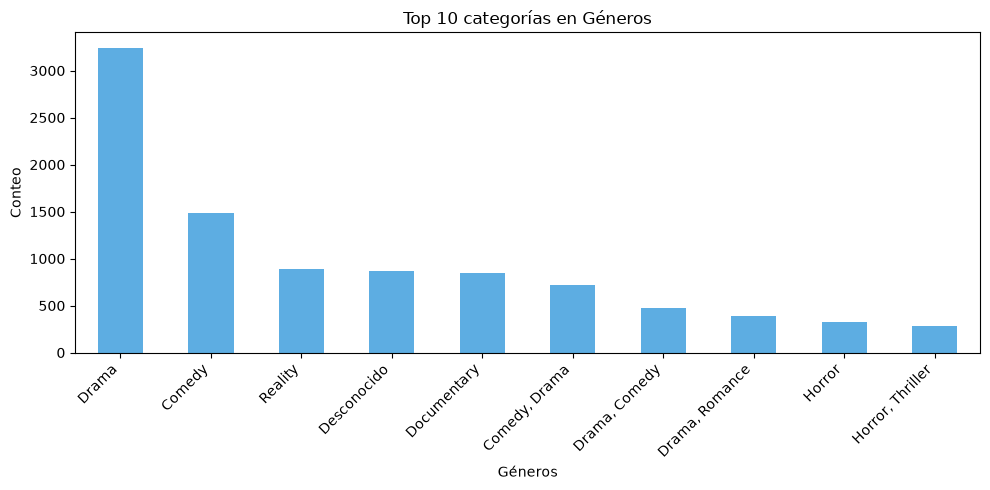


Top categorías de country:
country
United States of America    6201
Japan                       2064
Desconocido                 1813
South Korea                 1627
China                       1623
United Kingdom               874
France                       673
India                        614
Canada                       579
Germany                      446


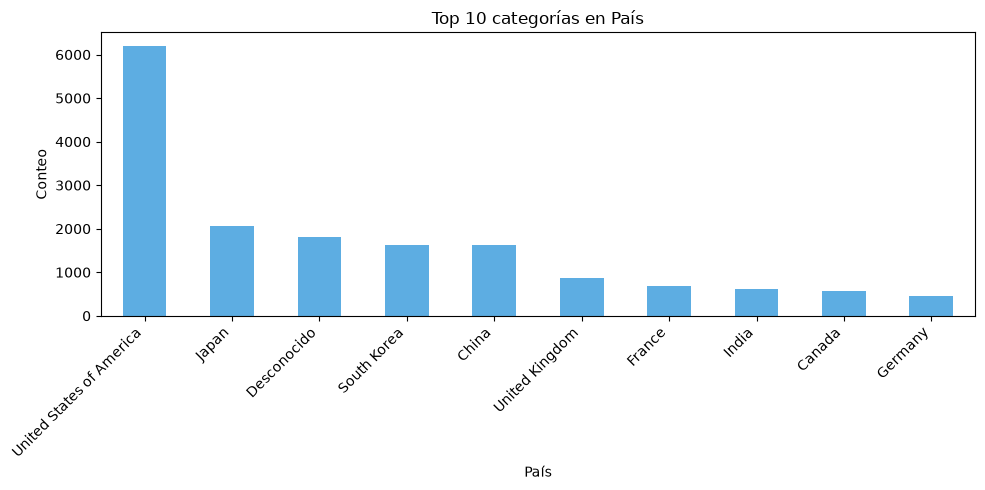


Top categorías de language:
language
en    11161
zh     2281
ja     2226
ko     1820
es     1329
fr     1293
de      578
hi      512
tl      419
pt      376


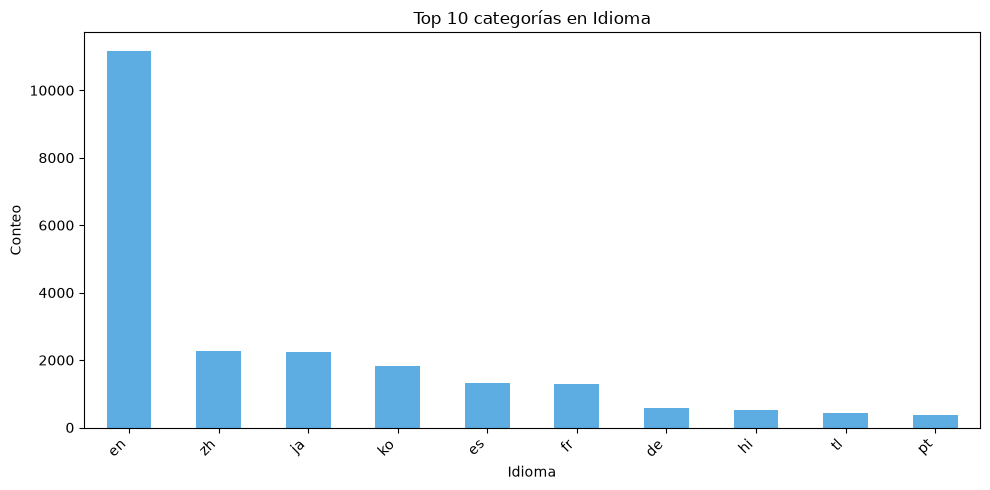


Top categorías de rating:
rating
0.0    3701
7.0     976
6.0     904
8.0     680
6.5     618
6.8     595
6.7     594
7.2     579
6.9     534
7.3     526


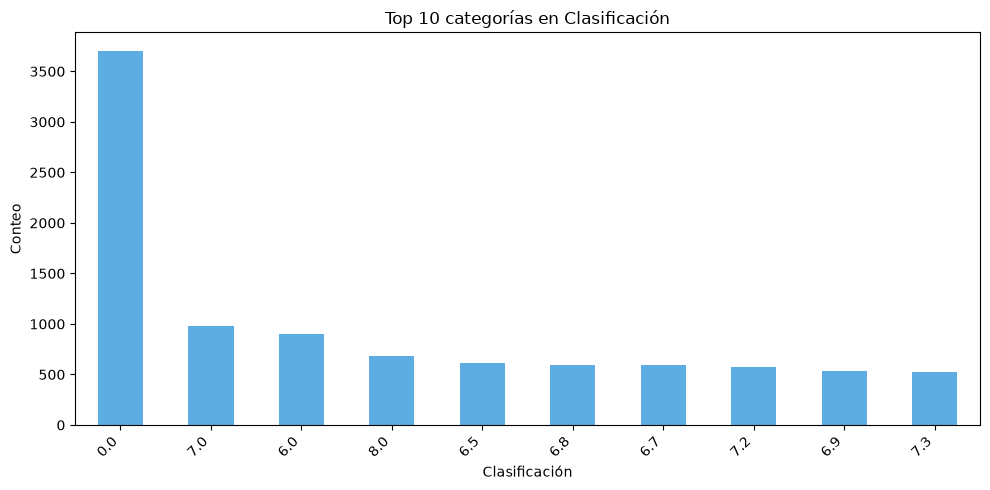


Top categorías de type:
type
TV Show    12800
Movie      12800


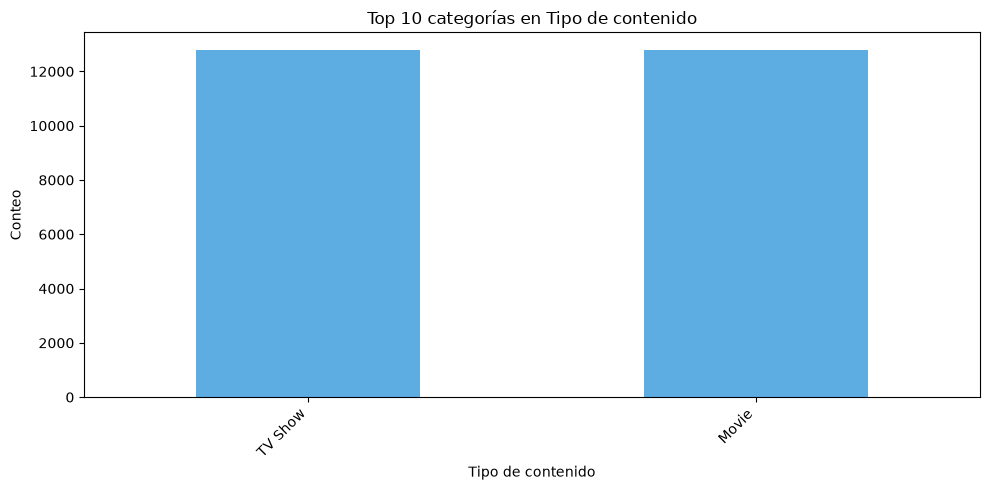

In [18]:
categorical_cols = [col for col in ['genres', 'country', 'language', 'rating', 'type'] if col in train.columns]
print('Variables categóricas analizadas:')
print(categorical_cols)

for col in categorical_cols:
    counts = train[col].astype(str).value_counts().head(10)
    print(f'\nTop categorías de {col}:')
    print(counts.to_string())

    fig, ax = plt.subplots(figsize=(10, 5))
    counts.plot(kind='bar', color='#5dade2', ax=ax)
    ax.set_title(f'Top 10 categorías en {variables_es.get(col, col)}')
    ax.set_xlabel(variables_es.get(col, col))
    ax.set_ylabel('Conteo')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    fig.savefig(images_dir / f'04_categorical_{col}.png', dpi=300, bbox_inches='tight')
    plt.show()


## Conclusión interna: variables categóricas

Las categorías más frecuentes permiten identificar segmentación clara del catálogo, especialmente en géneros, idiomas y países. Estos perfiles no solo describen la composición del dataset, sino que también aportan valor predictivo al distinguir tipos de contenido con patrones distintos de consumo y rendimiento.

La exploración categórica explica por qué el negocio no se puede resumir solo en métricas numéricas: el contexto del contenido, su origen y clasificación influencian su comportamiento. Los gráficos se mantienen en la carpeta de imágenes para revisión documental y comparativa.


Matriz de correlación de indicadores clave:
              popularity  vote_average  vote_count  indice_exito
popularity         1.000         0.039       0.069         0.096
vote_average       0.039         1.000       0.129         0.890
vote_count         0.069         0.129       1.000         0.342
indice_exito       0.096         0.890       0.342         1.000


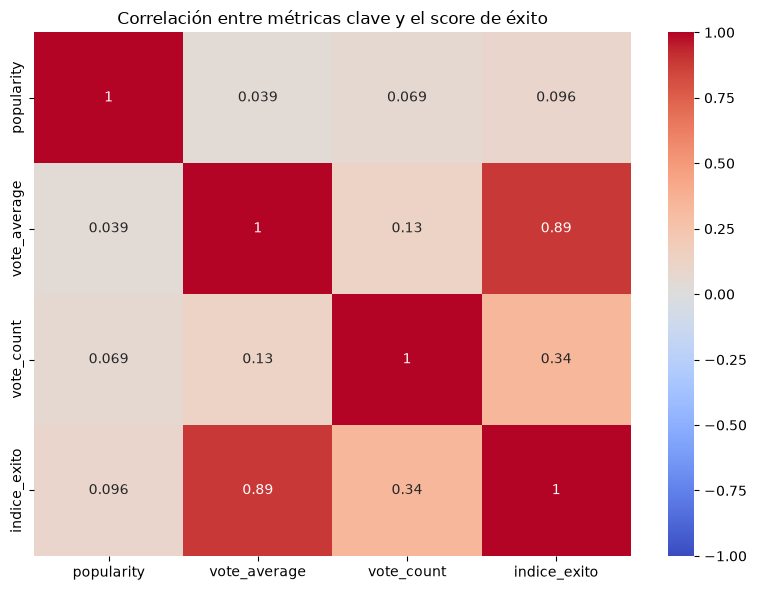

C:\Users\admin\AppData\Local\Temp\ipykernel_8856\3942683738.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


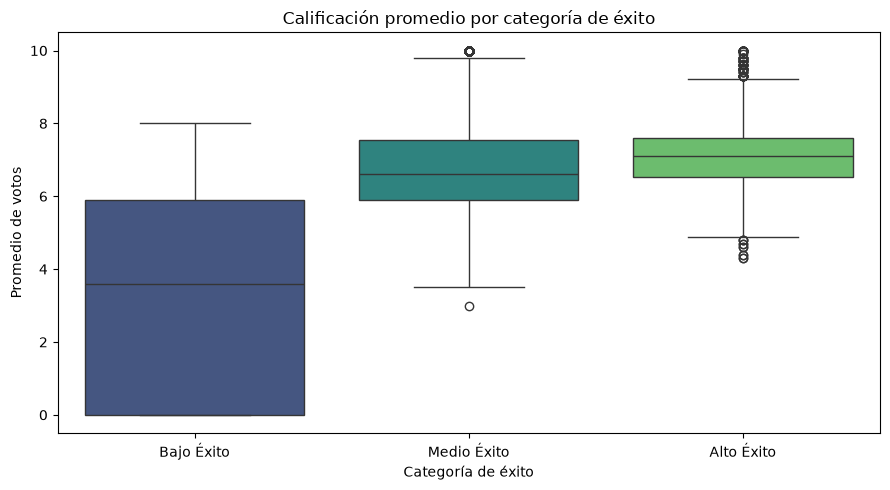

C:\Users\admin\AppData\Local\Temp\ipykernel_8856\3942683738.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


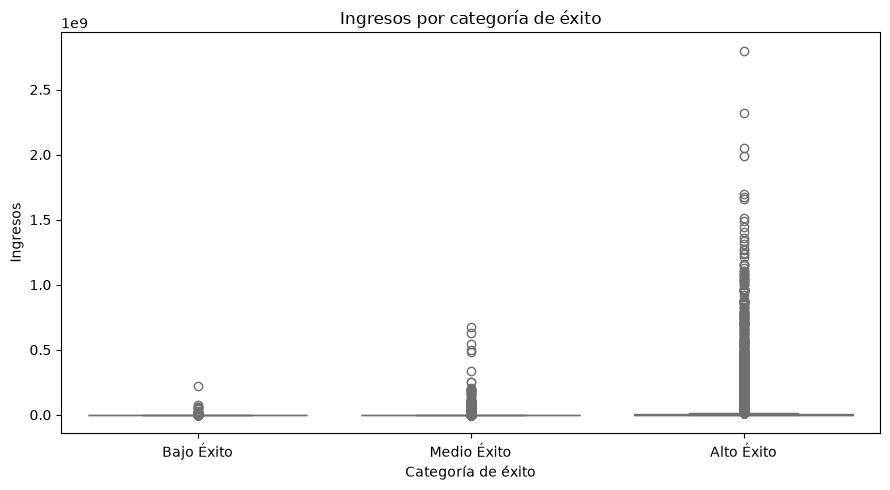

In [19]:
if {'categoria_exito', 'popularity', 'vote_average', 'vote_count', 'indice_exito'}.issubset(train.columns):
    corr = train[['popularity', 'vote_average', 'vote_count', 'indice_exito']].corr()
    print('Matriz de correlación de indicadores clave:')
    print(corr.round(3).to_string())

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title('Correlación entre métricas clave y el score de éxito')
    plt.tight_layout()
    fig.savefig(images_dir / '05_relaciones_metricas.png', dpi=300, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(
        data=train,
        x='categoria_exito',
        y='vote_average',
        order=['Bajo Éxito', 'Medio Éxito', 'Alto Éxito'],
        palette='viridis',
        ax=ax,
    )
    ax.set_title('Calificación promedio por categoría de éxito')
    ax.set_xlabel('Categoría de éxito')
    ax.set_ylabel(variables_es.get('vote_average', 'Promedio de votos'))
    plt.tight_layout()
    fig.savefig(images_dir / '06_vote_average_by_categoria_exito.png', dpi=300, bbox_inches='tight')
    plt.show()

if {'categoria_exito', 'budget', 'revenue'}.issubset(train.columns):
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(
        data=train,
        x='categoria_exito',
        y='revenue',
        order=['Bajo Éxito', 'Medio Éxito', 'Alto Éxito'],
        palette='pastel',
        ax=ax,
    )
    ax.set_title('Ingresos por categoría de éxito')
    ax.set_xlabel('Categoría de éxito')
    ax.set_ylabel(variables_es.get('revenue', 'Ingresos'))
    plt.tight_layout()
    fig.savefig(images_dir / '07_revenue_by_categoria_exito.png', dpi=300, bbox_inches='tight')
    plt.show()


## Conclusión interna: relaciones e insights

La relación entre popularidad, valoración y volumen de votos confirma que las métricas de engagement no son independientes; están fuertemente alineadas con el comportamiento general del contenido. En contraste, la relación con ingresos muestra cómo el éxito percibido por la audiencia puede traducirse o no en rendimiento financiero directo.

Este conjunto de relaciones permite interpretar el catálogo como un ecosistema heterogéneo: hay títulos muy visibles pero no necesariamente más rentables, y otros con mejor valoración que terminan con una menor presencia. Este tipo de insight es útil para construir la narrativa de negocio y para definir la siguiente etapa del proyecto con objetivos de predicción más claros.


## Conclusión de la fase 3: diagnóstico exploratorio del train

Hallazgos clave:
- La variable objetivo presenta una distribución útil para clasificación y no exige un tratamiento extremo de balanceo en la etapa inicial.
- Las variables numéricas muestran patrones de comportamiento claros en popularidad, votos y calificación, con potencial predictivo para el problema de negocio.
- Las categorías de géneros y países aportan segmentación útil del catálogo y permiten interpretar diferencias entre tipos de contenido.
- La exploración confirma que el dataset conserva información relevante para modelado y para la construcción de KPIs de dashboard.


## Fase 4: Ingeniería de Características y ETL

1. Feature Engineering: se crean variables útiles para análisis y dashboard.
2. Selección de Variables (Diagnóstico): se revisan columnas con valor analítico y sin leakage.
3. ETL Final (Train): se prepara la base final para modelado.
4. Guardado: se exporta train_procesado.csv y test_procesado.csv.

In [20]:
train['vote_count_log'] = np.log1p(train['vote_count'].clip(lower=0))
train['budget_log'] = np.log1p(train['budget'].clip(lower=0))
train['revenue_log'] = np.log1p(train['revenue'].clip(lower=0))

if {'budget', 'revenue'}.issubset(train.columns):
    train['profit'] = train['revenue'] - train['budget']
    train['roi'] = np.where(train['budget'] > 0, train['profit'] / train['budget'], np.nan)
    train['roi'] = train['roi'].fillna(0)

if 'vote_average' in train.columns:
    train['score_index'] = train['vote_average'] * train['vote_count']

print('Feature engineering finalizado. Variables generadas:')
print([c for c in ['vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index'] if c in train.columns])

Feature engineering finalizado. Variables generadas:
['vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index']


In [21]:
if 'indice_exito' in train.columns:
    train['target'] = train['indice_exito'].copy()
elif {'popularity', 'vote_average', 'vote_count'}.issubset(train.columns):
    train = compute_success_target(train)
    train['target'] = train['indice_exito'].copy()

selected_cols = [
    'type', 'title', 'country', 'genres', 'language', 'rating', 'release_year',
    'popularity', 'vote_count', 'vote_average', 'budget', 'revenue',
    'vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index',
    'indice_exito', 'categoria_exito', 'target'
]
selected = [c for c in selected_cols if c in train.columns]
print(f'Variables seleccionadas: {selected}')
print(f'Cantidad final: {len(selected)}')


Variables seleccionadas: ['type', 'title', 'country', 'genres', 'language', 'rating', 'release_year', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index', 'indice_exito', 'categoria_exito', 'target']
Cantidad final: 21


In [22]:
# Aseguramos que tanto train como test conserven el target formal del proyecto
# y no se sobrescriba con una lógica arbitraria de umbrales.

train_final = train.copy()
test_final = X_test.copy()

if 'indice_exito' not in train_final.columns:
    train_final = compute_success_target(train_final)

if 'target' not in train_final.columns:
    train_final['target'] = train_final['indice_exito'].copy()

if 'indice_exito' not in test_final.columns:
    test_final = compute_success_target(test_final)

if 'target' not in test_final.columns:
    test_final['target'] = test_final['indice_exito'].copy()

for column in ['popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'release_year']:
    if column in test_final.columns:
        test_final[column] = pd.to_numeric(test_final[column], errors='coerce')

for column in ['country', 'genres', 'language', 'rating', 'type']:
    if column in test_final.columns:
        test_final[column] = test_final[column].fillna('Desconocido')

for column in ['popularity', 'vote_average', 'vote_count', 'budget', 'revenue']:
    if column in test_final.columns:
        median_value = test_final[column].median()
        test_final[column] = test_final[column].fillna(median_value)

if 'release_year' in test_final.columns:
    test_final['release_year'] = pd.to_numeric(test_final['release_year'], errors='coerce')
    test_final['release_year'] = test_final['release_year'].replace({0: np.nan})
    test_final['release_year'] = test_final['release_year'].fillna(test_final['release_year'].median())

# Feature engineering en test para mantener compatibilidad con train
if 'vote_count' in test_final.columns:
    test_final['vote_count_log'] = np.log1p(test_final['vote_count'].clip(lower=0))
if 'budget' in test_final.columns:
    test_final['budget_log'] = np.log1p(test_final['budget'].clip(lower=0))
if 'revenue' in test_final.columns:
    test_final['revenue_log'] = np.log1p(test_final['revenue'].clip(lower=0))

if {'budget', 'revenue'}.issubset(test_final.columns):
    test_final['profit'] = test_final['revenue'] - test_final['budget']
    test_final['roi'] = np.where(test_final['budget'] > 0, test_final['profit'] / test_final['budget'], np.nan)
    test_final['roi'] = test_final['roi'].fillna(0)

if 'vote_average' in test_final.columns and 'vote_count' in test_final.columns:
    test_final['score_index'] = test_final['vote_average'] * test_final['vote_count']

selected_cols = [
    'type', 'title', 'country', 'genres', 'language', 'rating', 'release_year',
    'popularity', 'vote_count', 'vote_average', 'budget', 'revenue',
    'vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index',
    'indice_exito', 'categoria_exito', 'target'
]
selected_cols = [c for c in selected_cols if c in train_final.columns and c in test_final.columns]

for c in selected_cols:
    if c in train_final.columns and train_final[c].isna().any():
        if pd.api.types.is_numeric_dtype(train_final[c]):
            train_final[c] = train_final[c].fillna(train_final[c].median())
        else:
            train_final[c] = train_final[c].fillna('Desconocido')

    if c in test_final.columns and test_final[c].isna().any():
        if pd.api.types.is_numeric_dtype(test_final[c]):
            test_final[c] = test_final[c].fillna(test_final[c].median())
        else:
            test_final[c] = test_final[c].fillna('Desconocido')

train_output = train_final[selected_cols].copy()
test_output = test_final[selected_cols].copy()

train_output.to_csv(processed_dir / 'train_procesado.csv', index=False)
test_output.to_csv(processed_dir / 'test_procesado.csv', index=False)

print(f'Se guardó train_procesado.csv en {processed_dir / "train_procesado.csv"}')
print(f'Se guardó test_procesado.csv en {processed_dir / "test_procesado.csv"}')
print(f'Columnas exportadas final: {selected_cols}')
print('Validación final del EDA: proceso completado y exportado.')


Se guardó train_procesado.csv en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\train_procesado.csv
Se guardó test_procesado.csv en C:\Users\admin\Documents\GitHub\visualizacion-de-datos-StreamView-Analytics\data\processed\test_procesado.csv
Columnas exportadas final: ['type', 'title', 'country', 'genres', 'language', 'rating', 'release_year', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'vote_count_log', 'budget_log', 'revenue_log', 'profit', 'roi', 'score_index', 'indice_exito', 'categoria_exito', 'target']
Validación final del EDA: proceso completado y exportado.


## Conclusión de la fase 4: preparación final para modelado

Hallazgos clave:
- La ingeniería de características agrega señales útiles como logaritmos, profit y score index que mejoran la interpretación del contenido.
- La base final seleccionada conserva las columnas con valor analítico y evita columnas redundantes o no útiles para el modelado.
- La exportación de train_procesado.csv y test_procesado.csv deja la información lista para la fase predictiva y para análisis reproducibles.
- Con esta preparación, el proyecto queda en una posición sólida para la etapa de modelado, validación y despliegue analítico.


## Conclusión del notebook

Hallazgos principales:
- Se validó la estructura del dataset y su calidad inicial.
- La limpieza y el split se aplicaron siguiendo el principio de reproducibilidad.
- Se identificaron variables clave para modelado y dashboard.
- La base quedó exportada en train_procesado.csv y test_procesado.csv.

Siguiente etapa: entrenar y evaluar modelos sobre el conjunto reservado.